<a href="https://colab.research.google.com/github/Aditigk1203/ADITI-G-KRISHNAN/blob/main/Master_EDA_phase_1_2_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phase 1

ADITI KRISHNAN

23BDS0054

PHASE 1 PROJECT - EDA

DATASET - https://raw.githubusercontent.com/salemprakash/EDA/main/Data/stars%20type.csv


# STEP 1 : Loading the dataset


In [ ]:
# importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# loading dataset
df = pd.read_csv("stars_type.csv")
df.head()

,Temperature (K),Luminosity(L/Lo),Radius(R/Ro),Absolute magnitude(Mv),Star type,Star color,Spectral Class
0,3068,0.0024,0.1700,16.12,0,Red,M
1,3042,0.0005,0.1542,16.60,0,Red,M
2,2600,0.0003,0.1020,18.70,0,Red,M
3,2800,0.0002,0.1600,16.65,0,Red,M
4,1939,0.000138,0.1030,20.06,0,Red,M


# STEP 2 : Applying basic statistical analysis


In [ ]:
# dataset info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Temperature (K)         240 non-null    int64  
 1   Luminosity(L/Lo)        240 non-null    object 
 2   Radius(R/Ro)            240 non-null    float64
 3   Absolute magnitude(Mv)  240 non-null    float64
 4   Star type               240 non-null    int64  
 5   Star color              237 non-null    object 
 6   Spectral Class          240 non-null    object 
dtypes: float64(2), int64(2), object(3)
memory usage: 13.3+ KB


In [ ]:
# rows col count
df.shape

(240, 7)

In [ ]:
# cols names

df.columns

Index(['Temperature (K)', 'Luminosity(L/Lo)', 'Radius(R/Ro)',
       'Absolute magnitude(Mv)', 'Star type', 'Star color', 'Spectral Class'],
      dtype='object')

In [ ]:
# data type of cols
df.dtypes

,0
Temperature (K),int64
Luminosity(L/Lo),object
Radius(R/Ro),float64
Absolute magnitude(Mv),float64
Star type,int64
Star color,object
Spectral Class,object


In [ ]:
# statistical info
df.describe(include='all')

,Temperature (K),Luminosity(L/Lo),Radius(R/Ro),Absolute magnitude(Mv),Star type,Star color,Spectral Class
count,240.000000,240,240.000000,240.000000,240.000000,237,240
unique,NaN,208,NaN,NaN,NaN,19,8
top,NaN,200000,NaN,NaN,NaN,Red,M
freq,NaN,5,NaN,NaN,NaN,110,108
mean,10497.462500,NaN,237.157781,4.382396,2.500000,NaN,NaN
std,9552.425037,NaN,517.155763,10.532512,1.711394,NaN,NaN
min,1939.000000,NaN,0.008400,-11.920000,0.000000,NaN,NaN
25%,3344.250000,NaN,0.102750,-6.232500,1.000000,NaN,NaN
50%,5776.000000,NaN,0.762500,8.313000,2.500000,NaN,NaN
75%,15055.500000,NaN,42.750000,13.697500,4.000000,NaN,NaN


# STEP 3 : Handling missing data


In [ ]:
# checking values

df.isnull().sum()

,0
Temperature (K),0
Luminosity(L/Lo),0
Radius(R/Ro),0
Absolute magnitude(Mv),0
Star type,0
Star color,3
Spectral Class,0


In [ ]:
# percentage

(df.isnull().sum()/len(df))*100

,0
Temperature (K),0.00
Luminosity(L/Lo),0.00
Radius(R/Ro),0.00
Absolute magnitude(Mv),0.00
Star type,0.00
Star color,1.25
Spectral Class,0.00


In [ ]:
# fill using mode

df['Star color'].fillna(df['Star color'].mode()[0], inplace=True)

/tmp/ipykernel_5461/3646810259.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Star color'].fillna(df['Star color'].mode()[0], inplace=True)


In [ ]:
# verify

df.isnull().sum()

,0
Temperature (K),0
Luminosity(L/Lo),0
Radius(R/Ro),0
Absolute magnitude(Mv),0
Star type,0
Star color,0
Spectral Class,0


# STEP 4 Data cleaning



In [ ]:
# duplicate checkd
df.duplicated().sum()
#no dup

np.int64(0)

In [ ]:
df.dtypes

,0
Temperature (K),int64
Luminosity(L/Lo),object
Radius(R/Ro),float64
Absolute magnitude(Mv),float64
Star type,int64
Star color,object
Spectral Class,object


# STEP 5 Data transformation

In [ ]:
df.columns

Index(['Temperature (K)', 'Luminosity(L/Lo)', 'Radius(R/Ro)',
       'Absolute magnitude(Mv)', 'Star type', 'Star color', 'Spectral Class'],
      dtype='object')

In [ ]:
df.rename(columns={
    'Temperature (K)': 'Temperature',
    'Luminosity(L/Lo)': 'Luminosity',
    'Radius(R/Ro)': 'Radius',
    'Absolute magnitude(Mv)': 'Absolute_Magnitude',
    'Star color': 'Star_Color',
    'Spectral Class': 'Spectral_Class',
    'Star type': 'Star_Type'
}, inplace=True)

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['Star_Color'] = le.fit_transform(df['Star_Color'])
df['Spectral_Class'] = le.fit_transform(df['Spectral_Class'])

In [ ]:
df['Luminosity'] = pd.to_numeric(df['Luminosity'], errors='coerce')

In [ ]:
df['Luminosity'] = df['Luminosity'].fillna(df['Luminosity'].median())

In [ ]:
df.tail()

,Temperature,Luminosity,Radius,Absolute_Magnitude,Star_Type,Star_Color,Spectral_Class
235,38940,374830.0,1356.0,-9.93,5,0,7
236,30839,834042.0,1194.0,-10.63,5,0,7
237,8829,537493.0,1423.0,-10.73,5,11,1
238,9235,404940.0,1112.0,-11.23,5,11,1
239,37882,294903.0,1783.0,-7.80,5,0,7


In [ ]:
df.isnull().sum()

,0
Temperature,0
Luminosity,0
Radius,0
Absolute_Magnitude,0
Star_Type,0
Star_Color,0
Spectral_Class,0


In [ ]:
df.corr(numeric_only=True)

,Temperature,Luminosity,Radius,Absolute_Magnitude,Star_Type,Star_Color,Spectral_Class
Temperature,1.000000,0.374901,0.064216,-0.420261,0.411129,-0.692832,-0.174169
Luminosity,0.374901,1.000000,0.530908,-0.686880,0.671791,-0.378480,0.280427
Radius,0.064216,0.530908,1.000000,-0.608728,0.660975,-0.003973,0.110408
Absolute_Magnitude,-0.420261,-0.686880,-0.608728,1.000000,-0.955276,0.325286,-0.120811
Star_Type,0.411129,0.671791,0.660975,-0.955276,1.000000,-0.310879,-0.003410
Star_Color,-0.692832,-0.378480,-0.003973,0.325286,-0.310879,1.000000,-0.016581
Spectral_Class,-0.174169,0.280427,0.110408,-0.120811,-0.003410,-0.016581,1.000000


#STEP 6 Univariate Analysis

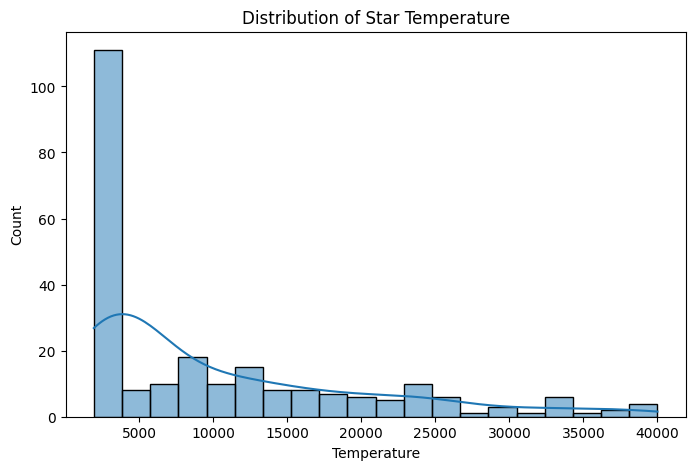

In [ ]:
#Histogram
plt.figure(figsize=(8,5))
sns.histplot(df['Temperature'], bins=20, kde=True)
plt.title("Distribution of Star Temperature")
plt.xlabel("Temperature")
plt.ylabel("Count")
plt.show()


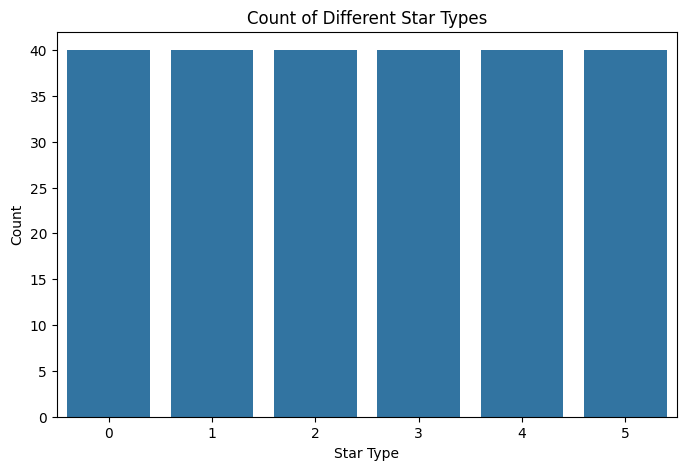

In [ ]:
#Count Plot:
plt.figure(figsize=(8,5))
sns.countplot(x='Star_Type', data=df)
plt.title("Count of Different Star Types")
plt.xlabel("Star Type")
plt.ylabel("Count")
plt.show()

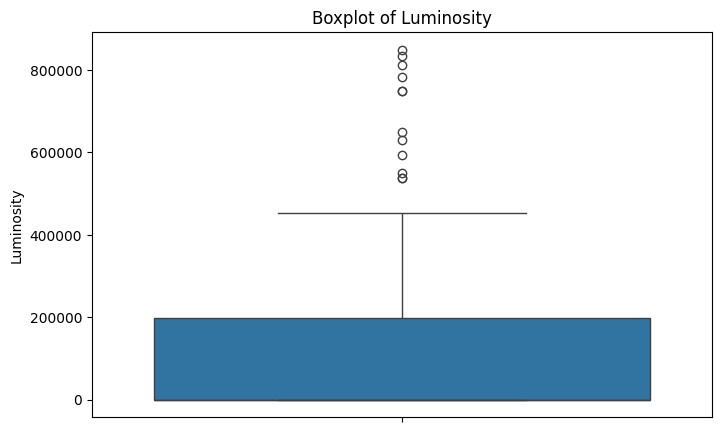

In [ ]:
#Box Plot
plt.figure(figsize=(8,5))
sns.boxplot(y=df['Luminosity'])
plt.title("Boxplot of Luminosity")
plt.ylabel("Luminosity")
plt.show()

# STEP 7 Bivariate Analysis

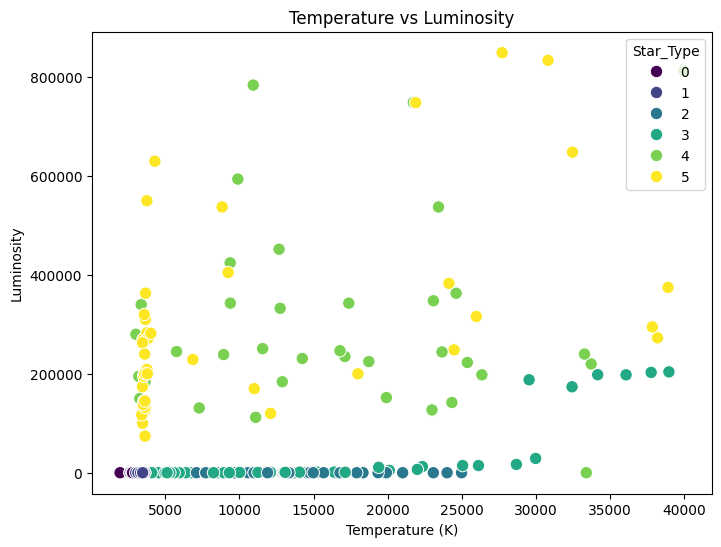

In [ ]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df,
    x='Temperature',
    y='Luminosity',
    hue='Star_Type',
    palette='viridis',
    s=80
)

plt.title("Temperature vs Luminosity")
plt.xlabel("Temperature (K)")
plt.ylabel("Luminosity")
plt.show()

/tmp/ipykernel_5461/2855270224.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


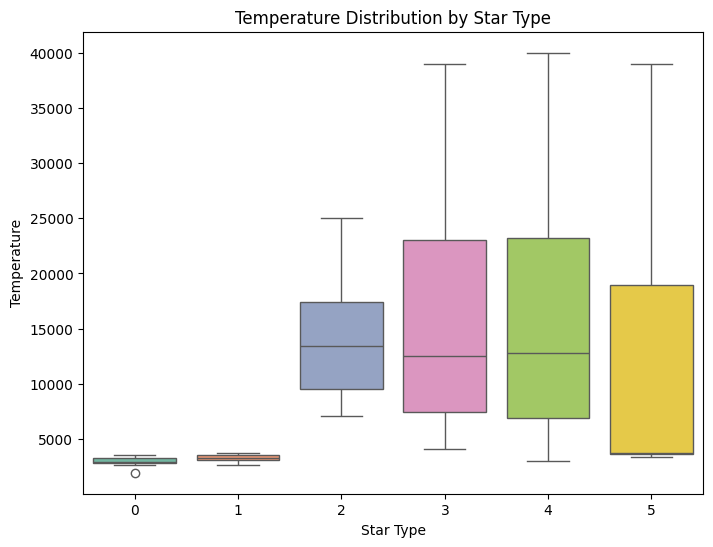

In [ ]:
plt.figure(figsize=(8,6))
sns.boxplot(
    data=df,
    x='Star_Type',
    y='Temperature',
    palette='Set2'
)

plt.title("Temperature Distribution by Star Type")
plt.xlabel("Star Type")
plt.ylabel("Temperature")
plt.show()

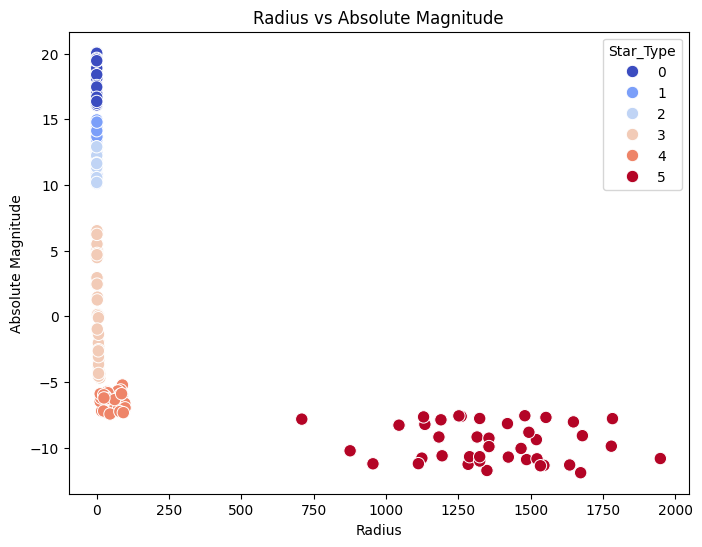

In [ ]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df,
    x='Radius',
    y='Absolute_Magnitude',
    hue='Star_Type',
    palette='coolwarm',
    s=80
)

plt.title("Radius vs Absolute Magnitude")
plt.xlabel("Radius")
plt.ylabel("Absolute Magnitude")
plt.show()

#STEP 8 Multivariate Analysis

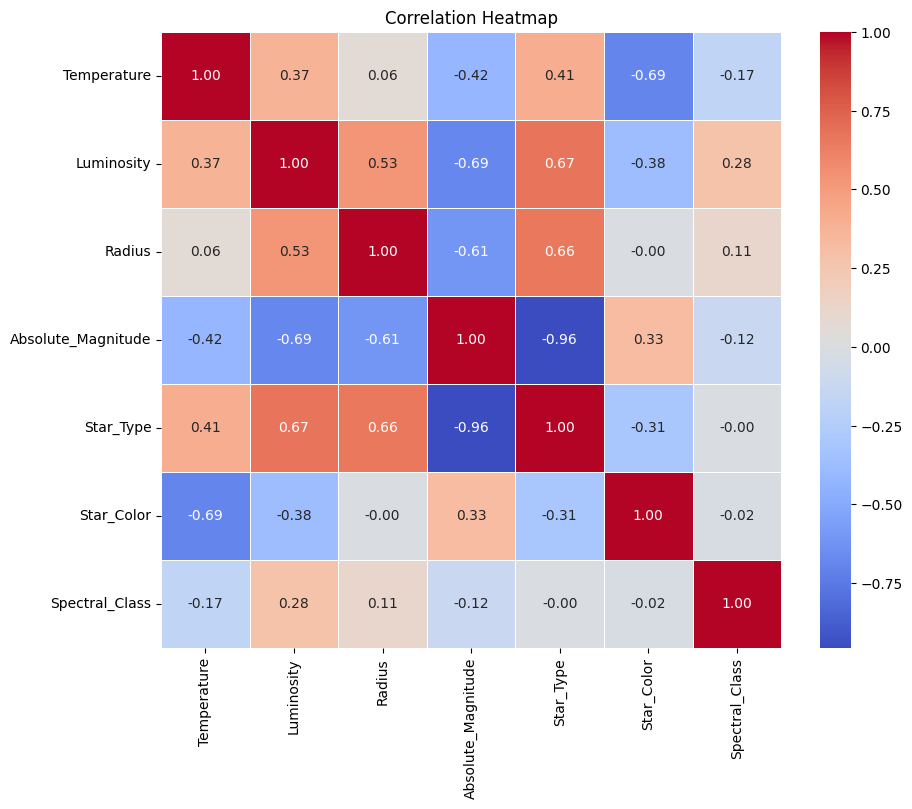

In [ ]:
plt.figure(figsize=(10,8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    linewidths=0.5,
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

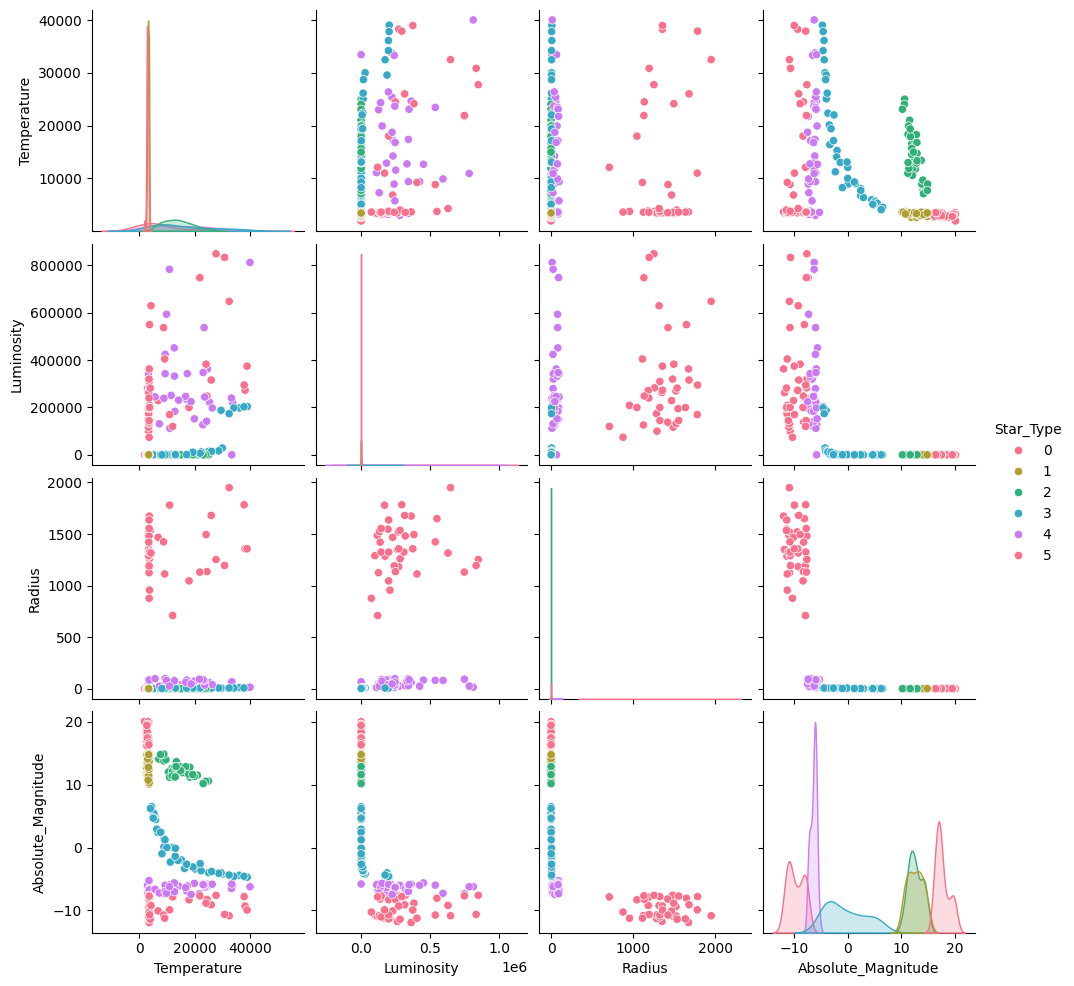

In [ ]:
sns.pairplot(
    df,
    vars=['Temperature','Luminosity','Radius','Absolute_Magnitude'],
    hue='Star_Type',
    palette='husl'
)

plt.show()

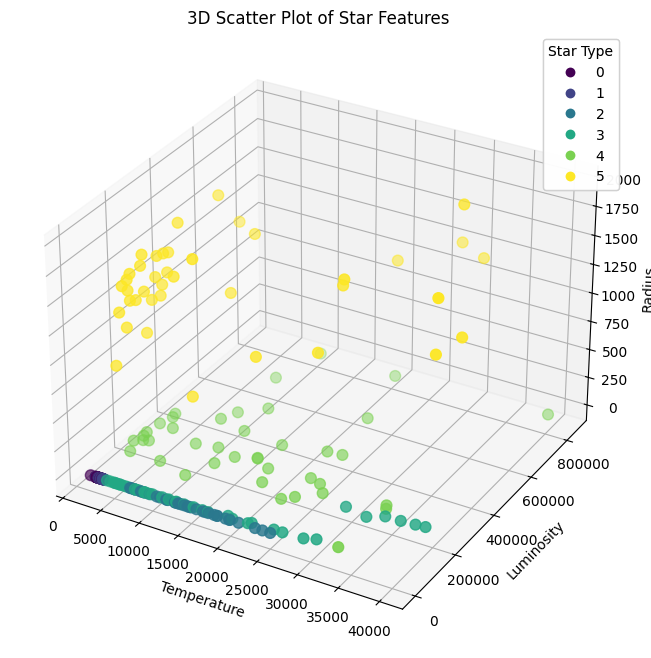

In [ ]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10,8))

ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    df['Temperature'],
    df['Luminosity'],
    df['Radius'],
    c=df['Star_Type'],
    cmap='viridis',
    s=60
)

ax.set_xlabel("Temperature")
ax.set_ylabel("Luminosity")
ax.set_zlabel("Radius")

plt.title("3D Scatter Plot of Star Features")

legend = ax.legend(*scatter.legend_elements(), title="Star Type")
ax.add_artist(legend)

plt.show()

# Phase 2

In [ ]:
#23BDS0054
#ADITI KRISHNAN
#EDA
#PHASE 2 PROJECT - EDA

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("stars_type.csv")

print(df.head())
print(df.shape)
print(df.info())

   Temperature (K) Luminosity(L/Lo)  Radius(R/Ro)  Absolute magnitude(Mv)  \
0             3068           0.0024        0.1700                   16.12   
1             3042           0.0005        0.1542                   16.60   
2             2600           0.0003        0.1020                   18.70   
3             2800           0.0002        0.1600                   16.65   
4             1939         0.000138        0.1030                   20.06   

   Star type Star color Spectral Class  
0          0        Red              M  
1          0        Red              M  
2          0        Red              M  
3          0        Red              M  
4          0        Red              M  
(240, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Temperature (K)         240 non-null    int64  
 1   Luminosity(L/L

In [ ]:
num_cols = [
    "Temperature (K)",
    "Luminosity(L/Lo)",
    "Radius(R/Ro)",
    "Absolute magnitude(Mv)"
]

for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(df[num_cols].describe())

       Temperature (K)  Luminosity(L/Lo)  Radius(R/Ro)  Absolute magnitude(Mv)
count       240.000000        239.000000    240.000000              240.000000
mean      10497.462500     106164.045156    237.157781                4.382396
std        9552.425037     179104.259253    517.155763               10.532512
min        1939.000000          0.000080      0.008400              -11.920000
25%        3344.250000          0.000860      0.102750               -6.232500
50%        5776.000000          0.056000      0.762500                8.313000
75%       15055.500000     198000.000000     42.750000               13.697500
max       40000.000000     849420.000000   1948.500000               20.060000


# 1D STATISTICAL ANALYSIS

In [ ]:
from scipy.stats import skew, kurtosis

x = df["Temperature (K)"]

stats = {
    "Mean": x.mean(),
    "Median": x.median(),
    "Minimum": x.min(),
    "Maximum": x.max(),
    "Range": x.max() - x.min(),
    "Variance": x.var(),
    "Standard Deviation": x.std(),
    "IQR": x.quantile(0.75) - x.quantile(0.25),
    "Skewness": skew(x.dropna()),
    "Kurtosis": kurtosis(x.dropna())
}

print(pd.Series(stats))

Mean                  1.049746e+04
Median                5.776000e+03
Minimum               1.939000e+03
Maximum               4.000000e+04
Range                 3.806100e+04
Variance              9.124882e+07
Standard Deviation    9.552425e+03
IQR                   1.171125e+04
Skewness              1.313294e+00
Kurtosis              8.342841e-01
dtype: float64


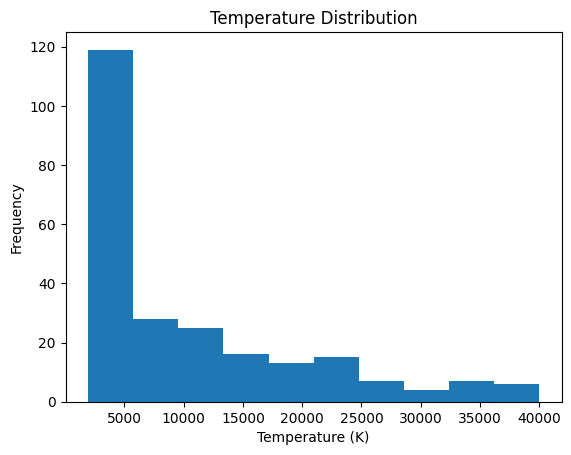

In [ ]:
plt.hist(df["Temperature (K)"], bins=10)
plt.xlabel("Temperature (K)")
plt.ylabel("Frequency")
plt.title("Temperature Distribution")
plt.show()

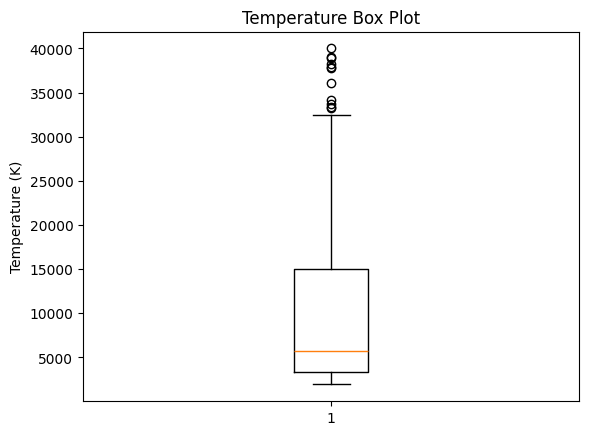

In [ ]:
plt.boxplot(df["Temperature (K)"].dropna())
plt.ylabel("Temperature (K)")
plt.title("Temperature Box Plot")
plt.show()

In [ ]:
freq = df["Star color"].value_counts()

print(freq)

Star color
Red                   110
Blue                   54
Blue-white             26
Blue White             10
yellow-white            8
White                   7
Yellowish White         3
Blue white              3
white                   3
Orange                  2
Whitish                 2
yellowish               2
Pale yellow orange      1
White-Yellow            1
Blue                    1
Yellowish               1
Orange-Red              1
Blue white              1
Blue-White              1
Name: count, dtype: int64


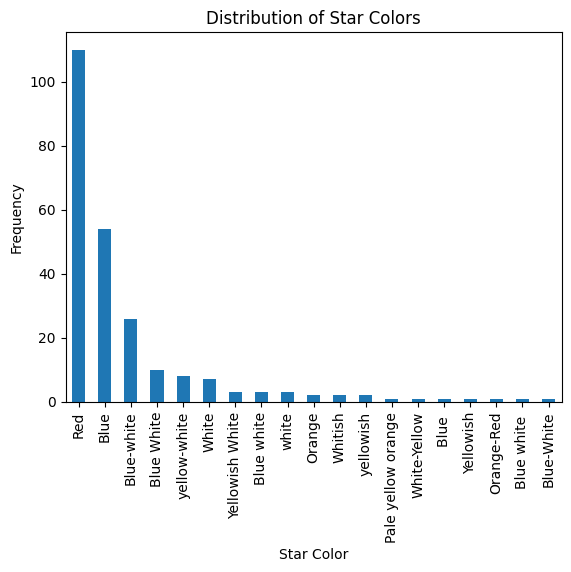

In [ ]:
freq.plot(kind="bar")
plt.xlabel("Star Color")
plt.ylabel("Frequency")
plt.title("Distribution of Star Colors")
plt.show()

# 2D STATISTICAL ANALYSIS

In [ ]:
x = df["Temperature (K)"]
y = df["Luminosity(L/Lo)"]

print("Pearson Correlation:")
print(x.corr(y))

Pearson Correlation:
0.3858373129295435


In [ ]:
print("Spearman Correlation:")
print(x.corr(y, method="spearman"))

Spearman Correlation:
0.4782014780125029


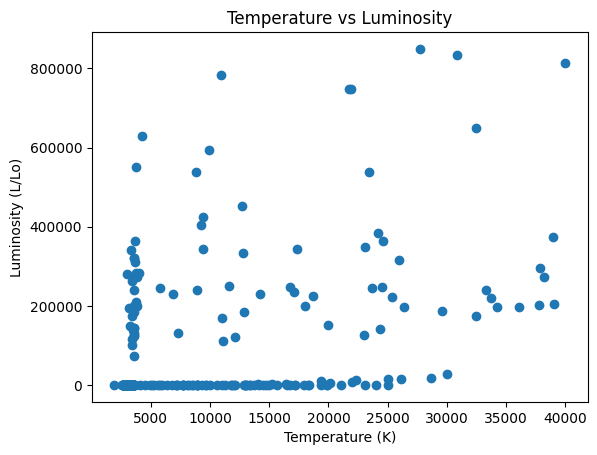

In [ ]:
plt.scatter(x, y)
plt.xlabel("Temperature (K)")
plt.ylabel("Luminosity (L/Lo)")
plt.title("Temperature vs Luminosity")
plt.show()

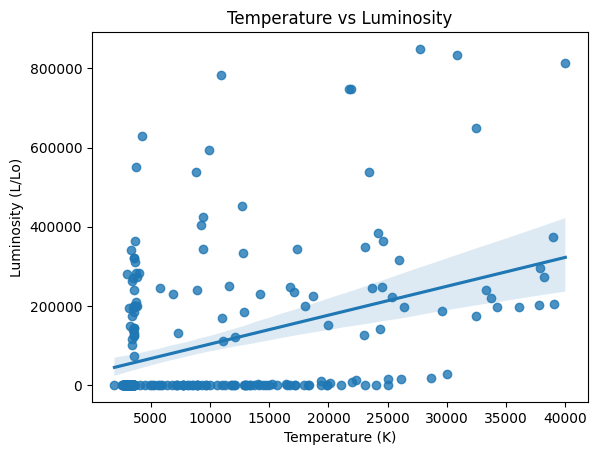

In [ ]:
sns.regplot(x=x, y=y)

plt.xlabel("Temperature (K)")
plt.ylabel("Luminosity (L/Lo)")
plt.title("Temperature vs Luminosity")
plt.show()

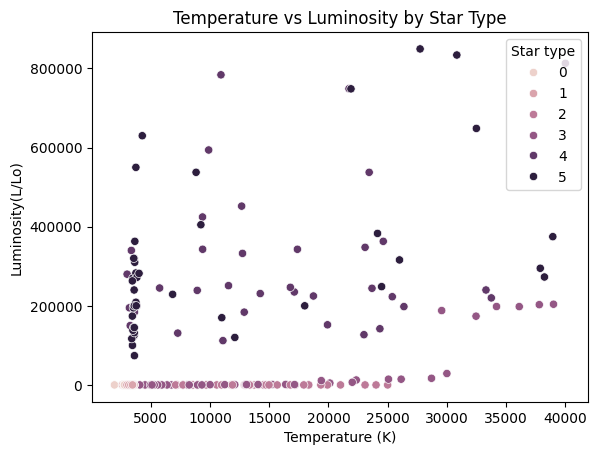

In [ ]:
sns.scatterplot(
    data=df,
    x="Temperature (K)",
    y="Luminosity(L/Lo)",
    hue="Star type"
)

plt.title("Temperature vs Luminosity by Star Type")
plt.show()

In [ ]:
print(df.groupby("Star color")["Temperature (K)"].mean())

Star color
Blue                  22015.425926
Blue                  19860.000000
Blue White            14638.900000
Blue white            10135.333333
Blue white            11900.000000
Blue-White             8945.000000
Blue-white            18669.923077
Orange                 4018.000000
Orange-Red             5112.000000
Pale yellow orange     7230.000000
Red                    3290.454545
White                  8545.857143
White-Yellow           7100.000000
Whitish                8876.000000
Yellowish              4980.000000
Yellowish White       10826.666667
white                 12460.666667
yellow-white           6466.250000
yellowish              4301.500000
Name: Temperature (K), dtype: float64


In [ ]:
print(df.groupby("Star color")["Temperature (K)"].agg(
    ["mean", "median", "std"]
))

                            mean   median          std
Star color                                            
Blue                22015.425926  20471.5  9616.112072
Blue                19860.000000  19860.0          NaN
Blue White          14638.900000  13760.0  4305.593892
Blue white          10135.333333   8924.0  2411.169288
Blue white          11900.000000  11900.0          NaN
Blue-White           8945.000000   8945.0          NaN
Blue-white          18669.923077  18270.0  6890.934218
Orange               4018.000000   4018.0   380.423448
Orange-Red           5112.000000   5112.0          NaN
Pale yellow orange   7230.000000   7230.0          NaN
Red                  3290.454545   3324.0   494.527235
White                8545.857143   8500.0  1136.878098
White-Yellow         7100.000000   7100.0          NaN
Whitish              8876.000000   8876.0  1165.311975
Yellowish            4980.000000   4980.0          NaN
Yellowish White     10826.666667  11790.0  2773.451520
white     

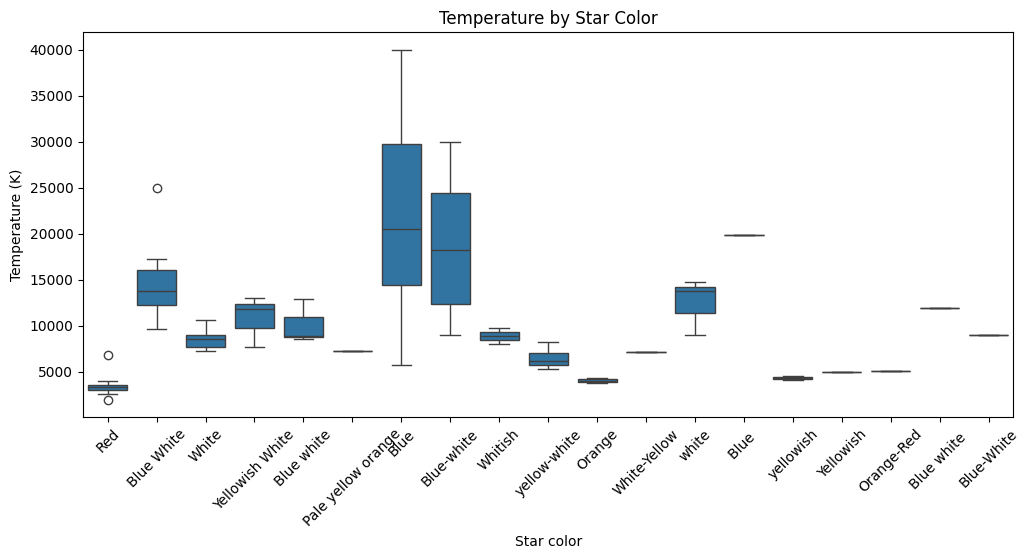

In [ ]:
plt.figure(figsize=(12,5))

sns.boxplot(
    data=df,
    x="Star color",
    y="Temperature (K)"
)

plt.xticks(rotation=45)
plt.title("Temperature by Star Color")
plt.show()

# 3D STATISTICAL Analysis

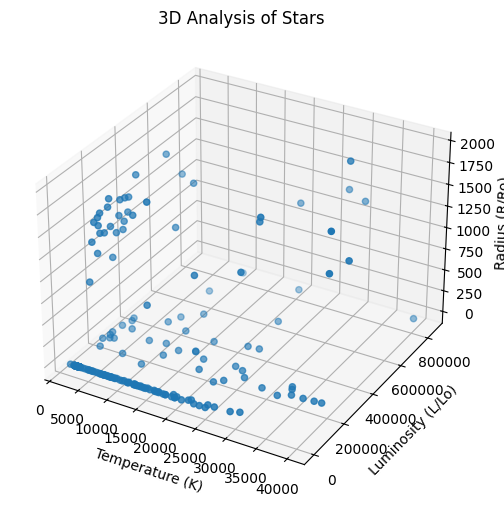

In [ ]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(8,6))

ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    df["Temperature (K)"],
    df["Luminosity(L/Lo)"],
    df["Radius(R/Ro)"]
)

ax.set_xlabel("Temperature (K)")
ax.set_ylabel("Luminosity (L/Lo)")
ax.set_zlabel("Radius (R/Ro)")

ax.set_title("3D Analysis of Stars")

plt.show()

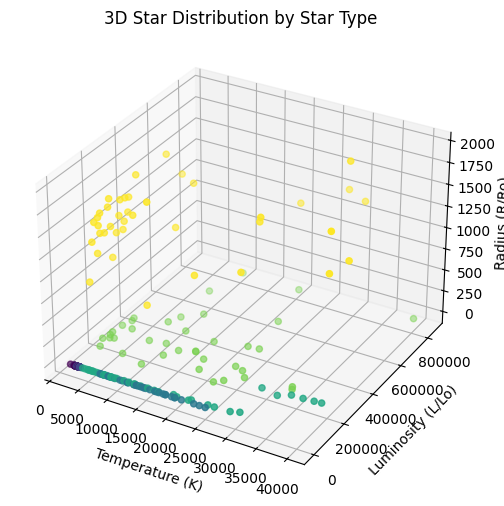

In [ ]:
fig = plt.figure(figsize=(8,6))

ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    df["Temperature (K)"],
    df["Luminosity(L/Lo)"],
    df["Radius(R/Ro)"],
    c=df["Star type"],
    cmap="viridis"
)

ax.set_xlabel("Temperature (K)")
ax.set_ylabel("Luminosity (L/Lo)")
ax.set_zlabel("Radius (R/Ro)")

ax.set_title("3D Star Distribution by Star Type")

plt.show()

In [ ]:
corr = df[num_cols].corr()

print(corr)

                        Temperature (K)  Luminosity(L/Lo)  Radius(R/Ro)  \
Temperature (K)                1.000000          0.385837      0.064216   
Luminosity(L/Lo)               0.385837          1.000000      0.530601   
Radius(R/Ro)                   0.064216          0.530601      1.000000   
Absolute magnitude(Mv)        -0.420261         -0.691141     -0.608728   

                        Absolute magnitude(Mv)  
Temperature (K)                      -0.420261  
Luminosity(L/Lo)                     -0.691141  
Radius(R/Ro)                         -0.608728  
Absolute magnitude(Mv)                1.000000  


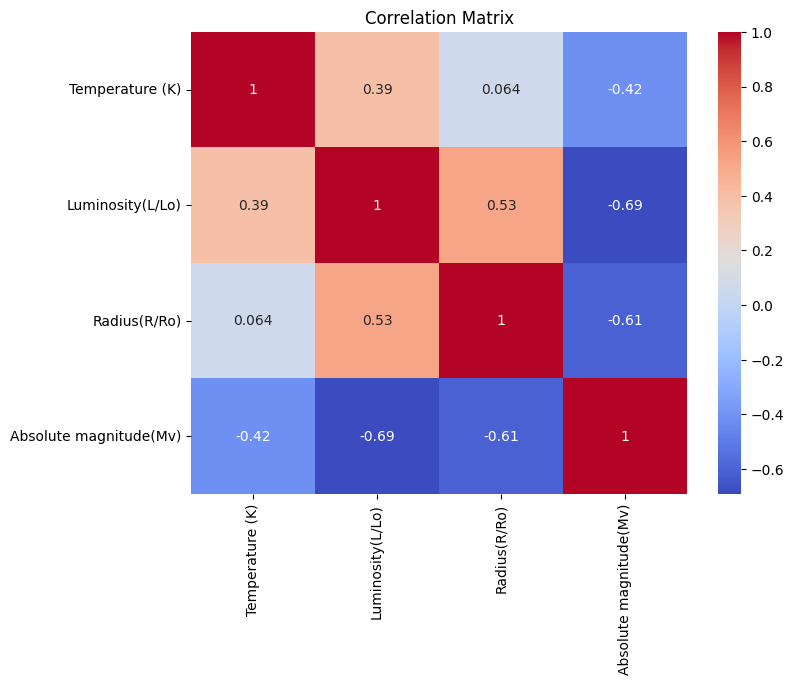

In [ ]:
plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Matrix")
plt.show()

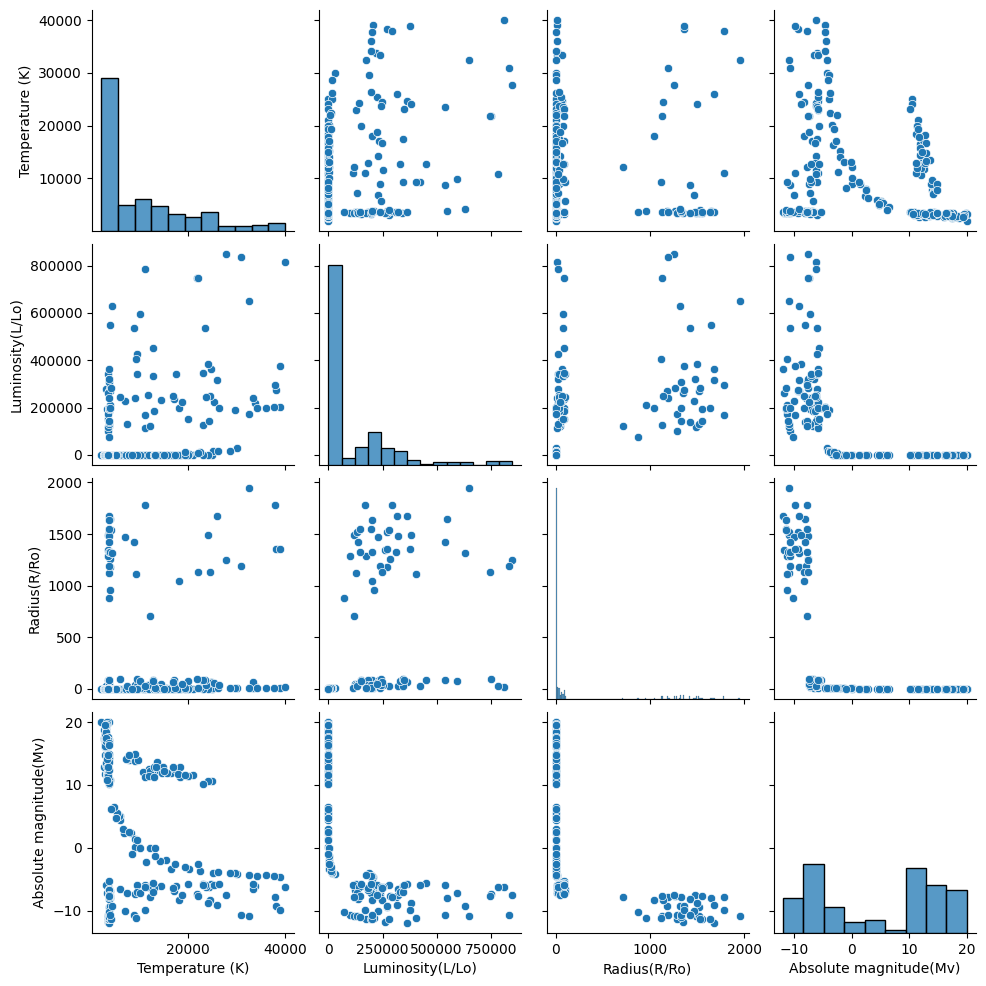

In [ ]:
sns.pairplot(df[num_cols])

plt.show()

# K-MEANS CLUSTERING

In [ ]:
X = df[num_cols].dropna()

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [ ]:
from sklearn.cluster import KMeans

wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=123, n_init=10)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

In [ ]:
kmeans = KMeans(
    n_clusters=6,
    random_state=123,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

print(clusters)

[5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 1 5 5 5 1 1 5 5 1 5 4 4 1 1 1 1 1
 1 1 1 0 0 0 0 0 0 0 0 0 4 3 3 3 3 3 3 3 3 3 3 5 5 5 5 5 5 5 5 5 5 5 5 5 5
 5 5 5 5 5 5 5 1 5 1 1 5 1 1 1 1 1 5 5 1 1 1 1 1 1 4 4 2 4 0 0 0 4 0 4 3 3
 3 3 3 3 3 3 3 3 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 1 1 1 1 1 5 1 1 5
 1 4 1 1 1 4 4 4 4 1 4 4 0 0 0 0 0 4 4 0 0 3 3 3 2 3 3 3 3 0 2 5 5 5 5 5 5
 5 5 5 5 5 5 5 5 5 5 5 5 5 5 1 1 1 1 1 1 1 1 1 1 4 1 1 4 4 4 1 1 1 1 4 0 0
 0 0 0 0 0 4 2 2 2 2 2 2 2 2 3 3 2]


In [ ]:
clustered = X.copy()

clustered["Cluster"] = clusters

print(clustered.head())

   Temperature (K)  Luminosity(L/Lo)  Radius(R/Ro)  Absolute magnitude(Mv)  \
0             3068          0.002400        0.1700                   16.12   
1             3042          0.000500        0.1542                   16.60   
2             2600          0.000300        0.1020                   18.70   
3             2800          0.000200        0.1600                   16.65   
4             1939          0.000138        0.1030                   20.06   

   Cluster  
0        5  
1        5  
2        5  
3        5  
4        5  


In [ ]:
print(clustered["Cluster"].value_counts())

Cluster
5    93
1    54
3    29
0    28
4    23
2    12
Name: count, dtype: int64


In [ ]:
print(kmeans.cluster_centers_)

[[-0.06764391  1.00892011 -0.31515033 -1.0434644 ]
 [ 0.30393242 -0.59200176 -0.45699404  0.23286106]
 [ 2.1158119   2.45173065  1.86616847 -1.24149935]
 [-0.58534574  0.81044904  2.18364322 -1.36700793]
 [ 1.85115287  0.26243373 -0.41177746 -0.88558021]
 [-0.7044038  -0.59399391 -0.45964415  0.98443089]]


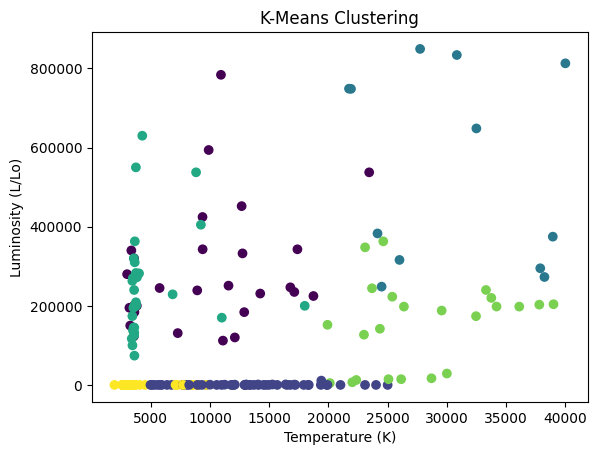

In [ ]:
plt.scatter(
    X["Temperature (K)"],
    X["Luminosity(L/Lo)"],
    c=clusters,
    cmap="viridis"
)

plt.xlabel("Temperature (K)")
plt.ylabel("Luminosity (L/Lo)")
plt.title("K-Means Clustering")
plt.show()

# HIERARCHICAL CLUSTERING

In [ ]:
X = df[num_cols].dropna()

In [ ]:
X_scaled = scaler.fit_transform(X)

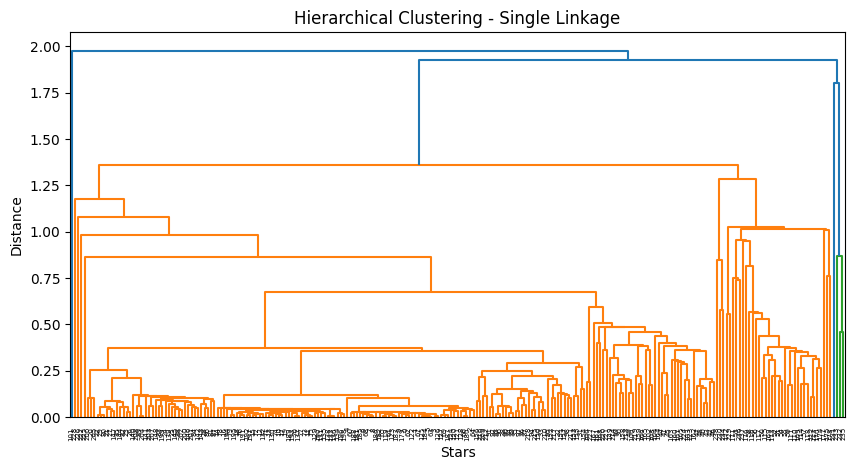

In [ ]:
#Single Linkage
from scipy.cluster.hierarchy import linkage, dendrogram

single = linkage(
    X_scaled,
    method="single",
    metric="euclidean"
)

plt.figure(figsize=(10,5))

dendrogram(single)

plt.title("Hierarchical Clustering - Single Linkage")
plt.xlabel("Stars")
plt.ylabel("Distance")

plt.show()

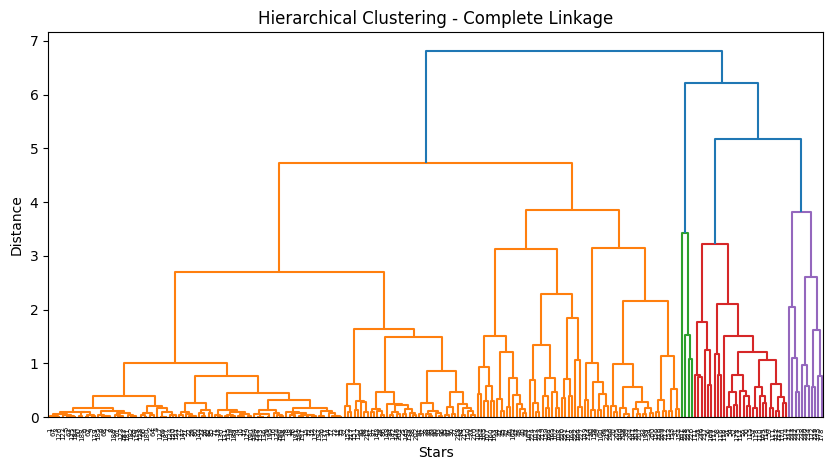

In [ ]:
#COMPLETE LINKAGE
complete = linkage(
    X_scaled,
    method="complete",
    metric="euclidean"
)

plt.figure(figsize=(10,5))

dendrogram(complete)

plt.title("Hierarchical Clustering - Complete Linkage")
plt.xlabel("Stars")
plt.ylabel("Distance")

plt.show()

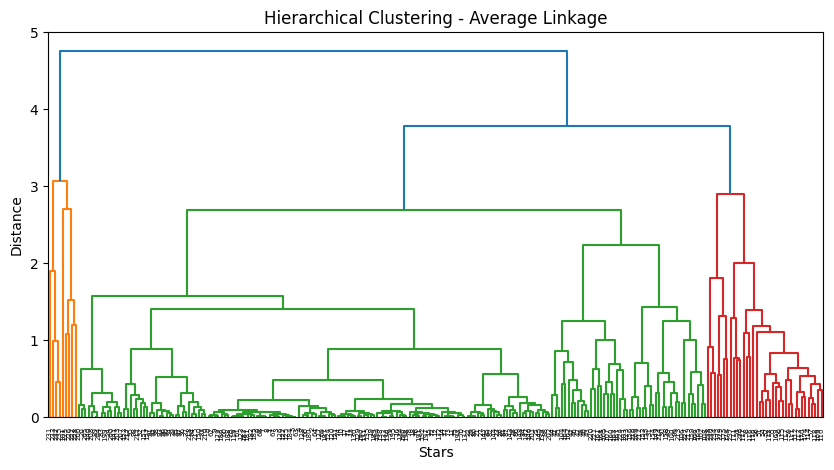

In [ ]:
#AVERAGE LINKAGE
average = linkage(
    X_scaled,
    method="average",
    metric="euclidean"
)

plt.figure(figsize=(10,5))

dendrogram(average)

plt.title("Hierarchical Clustering - Average Linkage")
plt.xlabel("Stars")
plt.ylabel("Distance")

plt.show()

In [ ]:
from scipy.cluster.hierarchy import fcluster

cluster_single = fcluster(single, 3, criterion="maxclust")
cluster_complete = fcluster(complete, 3, criterion="maxclust")
cluster_average = fcluster(average, 3, criterion="maxclust")

In [ ]:
# 3 HIERARCHICAL CLUSTERS
print("Single Linkage:")
print(cluster_single[:20])

print("\nComplete Linkage:")
print(cluster_complete[:20])

print("\nAverage Linkage:")
print(cluster_average[:20])

Single Linkage:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]

Complete Linkage:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]

Average Linkage:
[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2]


In [ ]:
#CLUSTER ASSIGNMENTS
print("Single Linkage:")
print(pd.Series(cluster_single).value_counts())

print("\nComplete Linkage:")
print(pd.Series(cluster_complete).value_counts())

print("\nAverage Linkage:")
print(pd.Series(cluster_average).value_counts())

Single Linkage:
1    234
2      4
3      1
Name: count, dtype: int64

Complete Linkage:
1    195
3     40
2      4
Name: count, dtype: int64

Average Linkage:
2    194
3     36
1      9
Name: count, dtype: int64


In [ ]:
#NUMBER OF SAMPLES IN EACH CLUSTER
print("Single Linkage:")
print(pd.Series(cluster_single).value_counts())

print("\nComplete Linkage:")
print(pd.Series(cluster_complete).value_counts())

print("\nAverage Linkage:")
print(pd.Series(cluster_average).value_counts())

Single Linkage:
1    234
2      4
3      1
Name: count, dtype: int64

Complete Linkage:
1    195
3     40
2      4
Name: count, dtype: int64

Average Linkage:
2    194
3     36
1      9
Name: count, dtype: int64


# Phase 3

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix

In [ ]:
# LOAD DATASET

uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(filename)

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

Saving stars_type.csv to stars_type.csv
Dataset shape: (240, 7)

First 5 rows:


,Temperature (K),Luminosity(L/Lo),Radius(R/Ro),Absolute magnitude(Mv),Star type,Star color,Spectral Class
0,3068,0.0024,0.1700,16.12,0,Red,M
1,3042,0.0005,0.1542,16.60,0,Red,M
2,2600,0.0003,0.1020,18.70,0,Red,M
3,2800,0.0002,0.1600,16.65,0,Red,M
4,1939,0.000138,0.1030,20.06,0,Red,M



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Temperature (K)         240 non-null    int64  
 1   Luminosity(L/Lo)        240 non-null    object 
 2   Radius(R/Ro)            240 non-null    float64
 3   Absolute magnitude(Mv)  240 non-null    float64
 4   Star type               240 non-null    int64  
 5   Star color              237 non-null    object 
 6   Spectral Class          240 non-null    object 
dtypes: float64(2), int64(2), object(3)
memory usage: 13.3+ KB


In [ ]:
# Clean names of columns
df.columns = df.columns.str.strip()

# Convertin lum into numeric
df["Luminosity(L/Lo)"] = pd.to_numeric(
    df["Luminosity(L/Lo)"], errors="coerce"
)

# Filling missing
numeric_cols = df.select_dtypes(include=np.number).columns
df[numeric_cols] = df[numeric_cols].fillna(
    df[numeric_cols].median()
)

# missing categorical values
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing values after cleaning:", df.isnull().sum().sum())



Missing values after cleaning: 0


In [ ]:
#PRINCIPAL COMPONENT ANALYSIS (PCA)

# numerical features only, excluding the target
X_pca = df.drop(columns=["Star type"]).select_dtypes(
    include=np.number
)

# Standardize data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_pca)


In [ ]:
# Reduce features
pca = PCA(n_components=2)
X_pca_result = pca.fit_transform(X_scaled)

In [ ]:
pca_df = pd.DataFrame(
    X_pca_result,
    columns=["Principal Component 1", "Principal Component 2"]
)

pca_df["Star type"] = df["Star type"].values

In [ ]:
print("\nOriginal number of numerical features:", X_pca.shape[1])
print("Number of principal components:", pca.n_components_)

print("\nExplained variance ratio:")
print("PC1:", round(pca.explained_variance_ratio_[0] * 100, 2), "%")
print("PC2:", round(pca.explained_variance_ratio_[1] * 100, 2), "%")

print(
    "Total variance retained:",
    round(sum(pca.explained_variance_ratio_) * 100, 2), "%"
)

print("\nFirst 5 PCA results:")
display(pca_df.head())


Original number of numerical features: 4
Number of principal components: 2

Explained variance ratio:
PC1: 60.14 %
PC2: 23.5 %
Total variance retained: 83.65 %

First 5 PCA results:


,Principal Component 1,Principal Component 2,Star type
0,1.470709,-0.359622,0
1,1.498300,-0.360876,0
2,1.630877,-0.394970,0
3,1.509829,-0.381858,0
4,1.730269,-0.449730,0


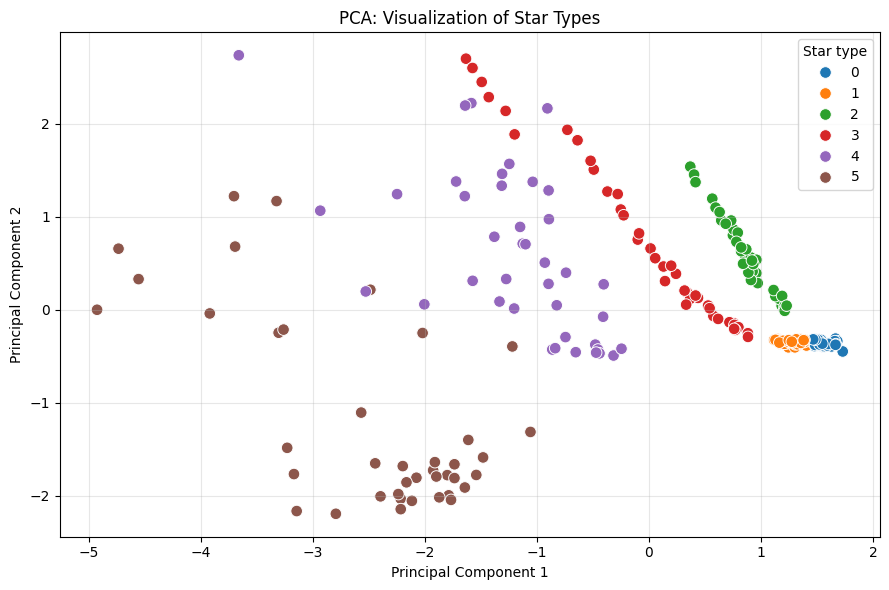

In [ ]:
# Visualize PCA results
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=pca_df,
    x="Principal Component 1",
    y="Principal Component 2",
    hue="Star type",
    palette="tab10",
    s=70
)
plt.title("PCA: Visualization of Star Types")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
#CLASSIFICATION USING RANDOM FOREST

X = df.drop(columns=["Star type"])
y = df["Star type"]

# Convert categorical numerical
X = pd.get_dummies(X, drop_first=False)

In [ ]:
# Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])



Training samples: 192
Testing samples: 48


In [ ]:
# Train
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [ ]:
# Predict star types
y_pred = model.predict(X_test)

In [ ]:
# accuracy
accuracy = accuracy_score(y_test, y_pred)

In [ ]:
print("Classification Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Classification Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         8
           1       1.00      1.00      1.00         8
           2       1.00      1.00      1.00         8
           3       1.00      1.00      1.00         8
           4       1.00      1.00      1.00         8
           5       1.00      1.00      1.00         8

    accuracy                           1.00        48
   macro avg       1.00      1.00      1.00        48
weighted avg       1.00      1.00      1.00        48



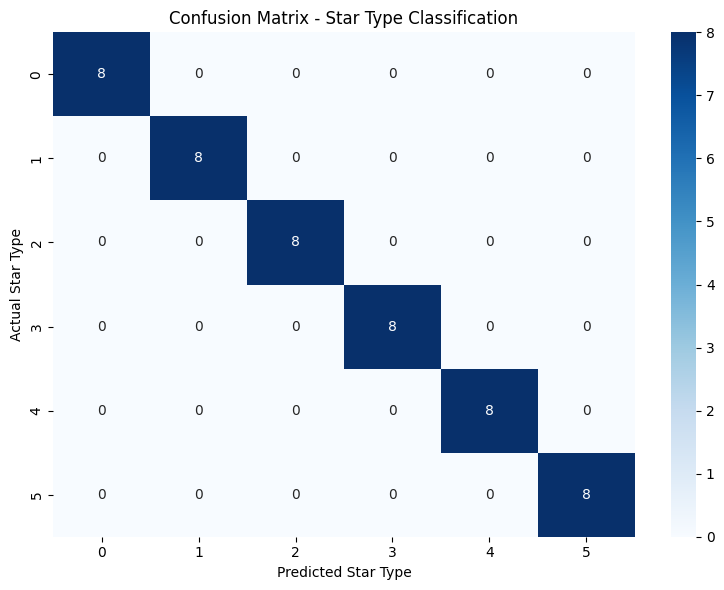

In [ ]:

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Confusion Matrix - Star Type Classification")
plt.xlabel("Predicted Star Type")
plt.ylabel("Actual Star Type")
plt.tight_layout()
plt.show()



In [ ]:
# Display feature importance
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nTop 10 Important Features:")
display(importance.head(10).to_frame("Importance"))


Top 10 Important Features:


,Importance
Absolute magnitude(Mv),0.255058
Radius(R/Ro),0.243599
Luminosity(L/Lo),0.182373
Temperature (K),0.107994
Star color_Red,0.058189
Spectral Class_O,0.037507
Spectral Class_M,0.030735
Star color_Blue-white,0.019717
Spectral Class_B,0.014632
Star color_Blue,0.013666


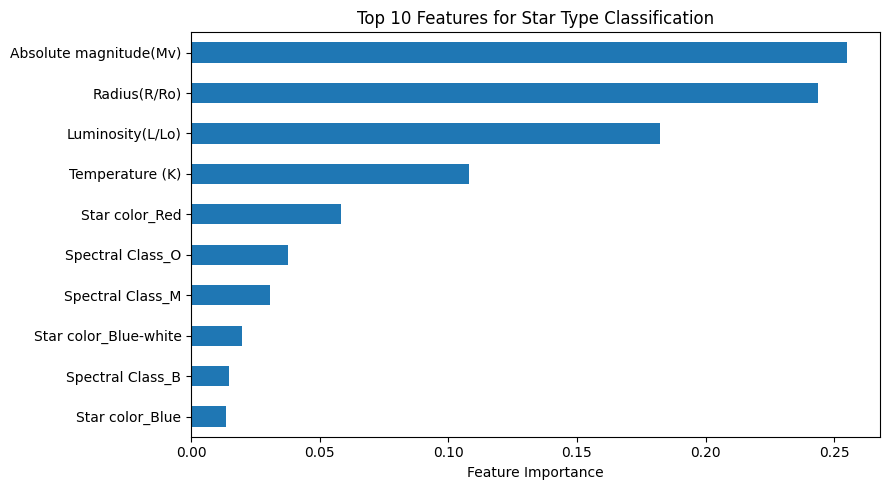

In [ ]:
plt.figure(figsize=(9, 5))
importance.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 Features for Star Type Classification")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()